# Chapter 5: Approximate Sets and Predicates

Companion notebook for **Chapter 5** of *Bernoulli Types: An Algebra of Approximate Computation*.
Source files: `book/chapters/ch05/`.

Chapter 5 lifts the noisy bit of Part I to a *predicate* on a universe: a Bernoulli set is
a noisy membership oracle, and a Bloom filter is the canonical one-sided realization
(false-negative rate $\omega = 0$, false-positive rate $\epsilon$ at most a target).

This notebook:

1. Builds a Bloom filter from scratch using a SHA-256 hash family.
2. Verifies the no-false-negatives guarantee on $n = 1000$ inserted items.
3. Measures the empirical false-positive rate at $m = 10000$, $n = 1000$, $k = 7$ and
   compares to the closed form $(1 - e^{-kn/m})^k$ from \S5.2.
4. Sweeps $k \in \{1, 2, \ldots, 15\}$ at fixed $(m, n)$ and reads off the empirical
   optimum, comparing to $k^* = (m/n) \ln 2$.
5. Walks $(m, n)$ across several capacity regimes and checks that the FPR at the
   integer-rounded $k^*$ lands near $(1/2)^{k^*}$.
6. Closes with the open question that chapter 8 (entropy floor) and chapter 14
   (perfect-hash filters) will pick up: what happens when bits run out?

**Conventions (matching book notation):**
- `epsilon` ($\epsilon$) = false-positive rate.
- `omega` ($\omega$) = false-negative rate; for a Bloom filter $\omega = 0$ exactly.
- `m` = bit-array length; `n` = number of inserted items; `k` = number of hash functions.
- A single seeded `rng` drives every random draw.

In [1]:
import hashlib
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

print(f"NumPy {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy 2.4.6
Matplotlib 3.10.9


## 1. A Bloom Filter From Scratch

**Definition (\S5.2, Definition 5.1):** A Bloom filter on a bit array $b[1 \ldots m]$,
initialized to zeros, with $k$ hash functions $h_1, \ldots, h_k : \mathcal{U} \to \{1, \ldots, m\}$.

- **Insert($x$):** set $b[h_i(x)] = 1$ for every $i \in \{1, \ldots, k\}$.
- **Query($x$):** return $\top$ if $b[h_i(x)] = 1$ for every $i$; otherwise $\bot$.

Section 5.2 treats the $h_i$ as independent uniform random functions. We approximate that
by computing a separate SHA-256 digest for each hash index: $h_i(x) = \mathrm{SHA256}(i \Vert x) \bmod m$.
The salt-by-index trick scales to any $k$ without exhausting a fixed digest budget,
and the practical bias against uniformity is well below the sampling noise of the
experiments below.

In [2]:
class BloomFilter:
    """Textbook Bloom filter: m bits, k SHA-256-derived hash functions.

    Hash family: h_i(x) = SHA256(str(i) + ':' + str(x)) mod m, for i in 0..k-1.
    The per-index salt gives a fresh digest for each hash function and scales
    to arbitrary k without a fixed-byte-budget limit.

    Parameters
    ----------
    m : int
        Number of bits in the underlying array.
    k : int
        Number of hash functions. Any positive integer.
    """

    def __init__(self, m: int, k: int) -> None:
        if m <= 0 or k <= 0:
            raise ValueError(f"need m > 0 and k > 0; got m={m}, k={k}")
        self.m = m
        self.k = k
        self.bits = np.zeros(m, dtype=bool)

    def _positions(self, x: object) -> list[int]:
        """Return the k bit positions that x hashes to."""
        key = str(x).encode("utf-8")
        positions = []
        for i in range(self.k):
            digest = hashlib.sha256(str(i).encode("utf-8") + b":" + key).digest()
            # Take the first 8 bytes as a 64-bit integer to avoid modular bias
            # at this m, then reduce modulo m.
            positions.append(int.from_bytes(digest[:8], "big") % self.m)
        return positions

    def add(self, x: object) -> None:
        """Insert x: set all k bits at positions h_i(x) to 1."""
        for pos in self._positions(x):
            self.bits[pos] = True

    def __contains__(self, x: object) -> bool:
        """Query x: return True iff all k bits at positions h_i(x) are 1."""
        return all(self.bits[pos] for pos in self._positions(x))

    def load(self) -> float:
        """Fraction of bits currently set to 1."""
        return float(self.bits.mean())


# Smoke test: an empty filter rejects everything.
bf_empty = BloomFilter(m=128, k=4)
assert ("anything" in bf_empty) is False, "empty filter must reject"
print("BloomFilter(m=128, k=4) rejects every query while empty: confirmed.")

# Smoke test: after inserting x, x is reported present.
bf_empty.add("hello")
assert ("hello" in bf_empty), "inserted item must be reported present"
print("After inserting 'hello', 'hello' in bf is True: confirmed.")

# Smoke test: scaling to k=15 works (relevant for Section 4's sweep).
bf_big_k = BloomFilter(m=10_000, k=15)
bf_big_k.add("foo")
assert ("foo" in bf_big_k), "k=15 filter must report its insert"
print("BloomFilter(m=10000, k=15) supports the full sweep range: confirmed.")

BloomFilter(m=128, k=4) rejects every query while empty: confirmed.
After inserting 'hello', 'hello' in bf is True: confirmed.
BloomFilter(m=10000, k=15) supports the full sweep range: confirmed.


## 2. The No-False-Negatives Guarantee

The structural fact about Bloom filters (\S5.2, also \S5.4 on the one-sided / two-sided
dichotomy): once we insert $x$, every bit it touches is set, and they stay set forever.
A subsequent query for $x$ reads exactly those bits, finds them all $1$, and returns
$\top$. There is no path by which an inserted item is reported absent. In rate language,
$\omega = 0$ exactly, not in expectation.

We verify on the parameter regime the rest of the notebook will use: $m = 10000$,
$k = 7$, $n = 1000$ random strings.

In [3]:
M_DEMO = 10_000
K_DEMO = 7
N_DEMO = 1_000


def random_string(rng: np.random.Generator, length: int = 16) -> str:
    """Draw a random lowercase string of the given length."""
    letters = np.array(list("abcdefghijklmnopqrstuvwxyz0123456789"))
    return "".join(letters[rng.integers(0, len(letters), size=length)])


bf = BloomFilter(m=M_DEMO, k=K_DEMO)
inserted = [random_string(rng) for _ in range(N_DEMO)]
for s in inserted:
    bf.add(s)

misses = sum(1 for s in inserted if s not in bf)

print(f"BloomFilter(m={M_DEMO}, k={K_DEMO}) after inserting n={N_DEMO} random strings:")
print(f"  bits set:        {int(bf.bits.sum()):,} of {M_DEMO:,}  (load = {bf.load():.4f})")
print(f"  membership misses among inserted items: {misses}")
print()
assert misses == 0, "Bloom filter must never miss an inserted item"
print("Zero misses: the no-false-negatives guarantee is structural, not statistical.")

BloomFilter(m=10000, k=7) after inserting n=1000 random strings:
  bits set:        5,005 of 10,000  (load = 0.5005)
  membership misses among inserted items: 0

Zero misses: the no-false-negatives guarantee is structural, not statistical.


## 3. Empirical FPR at the Standard Operating Point

Section 5.2 derives the false-positive rate by treating the $k$ bit-read events as
independent and the load-probability per bit as $p = 1 - (1 - 1/m)^{kn} \approx 1 - e^{-kn/m}$:

$$\epsilon \approx \left(1 - e^{-kn/m}\right)^k.$$

At $m = 10000$, $n = 1000$, $k = 7$: $kn/m = 0.7$, $1 - e^{-0.7} \approx 0.5034$, and
$\epsilon \approx 0.5034^7 \approx 0.0082$.

We query $10000$ random strings known to be absent (drawn fresh from a different prefix
so they cannot collide with the inserted set) and count the fraction reported $\top$.

In [4]:
N_QUERIES = 10_000
inserted_set = set(inserted)

queries = []
while len(queries) < N_QUERIES:
    candidate = "q:" + random_string(rng)
    if candidate not in inserted_set:
        queries.append(candidate)

fp_count = sum(1 for q in queries if q in bf)
empirical_fpr = fp_count / N_QUERIES

kn_over_m = K_DEMO * N_DEMO / M_DEMO
theoretical_fpr = (1.0 - np.exp(-kn_over_m)) ** K_DEMO

print(f"Empirical FPR at (m, n, k) = ({M_DEMO}, {N_DEMO}, {K_DEMO}) over {N_QUERIES:,} out-of-set queries:")
print(f"  false positives:   {fp_count}")
print(f"  empirical FPR:     {empirical_fpr:.4f}")
print(f"  theoretical FPR:   (1 - e^(-{kn_over_m}))^{K_DEMO} = {theoretical_fpr:.4f}")
print(f"  absolute error:    {abs(empirical_fpr - theoretical_fpr):.4f}")
print()
if abs(empirical_fpr - theoretical_fpr) < 0.005:
    print("Within +/- 0.005 of theory: the bit-independence approximation tracks reality here.")

Empirical FPR at (m, n, k) = (10000, 1000, 7) over 10,000 out-of-set queries:
  false positives:   77
  empirical FPR:     0.0077
  theoretical FPR:   (1 - e^(-0.7))^7 = 0.0082
  absolute error:    0.0005

Within +/- 0.005 of theory: the bit-independence approximation tracks reality here.


## 3b. The Same Filter, From the Library

The from-scratch class above is the pedagogy; `bernoulli.sets.BloomFilter` is the production version of the same object. You hand it a capacity and a target FPR, and it sizes the bit array and picks $k$ for you. It adds two things a hand-rolled filter does not: it reports its own configured FPR, and `query(x)` returns a `BernoulliBool`, the noisy bit of Part I, carrying the filter's $(\fprate, \fnrate = 0)$ rates so the answer composes under the chapter 3 algebra. AND-ing two independent filters then multiplies their false-positive rates, the same multiplicative suppression as a Miller-Rabin witness chain.

In [5]:
from bernoulli.sets import BloomFilter as LibBloom

# Same operating point as Section 3: n = 1000 keys, target FPR ~ 0.0082.
lib_bf = LibBloom(capacity=N_DEMO, target_fpr=theoretical_fpr)
for s in inserted:
    lib_bf.add(s.encode())

lib_misses = sum(1 for s in inserted if not lib_bf.contains(s.encode()))
lib_fp = sum(1 for q in queries if lib_bf.contains(q.encode()))

print(f"library BloomFilter(capacity={N_DEMO}, target_fpr={theoretical_fpr:.4f}):")
print(f"  sized to m = {lib_bf.num_bits} bits, k = {lib_bf.num_hashes} hashes "
      f"(the from-scratch filter used m = {M_DEMO}, k = {K_DEMO})")
print(f"  inserted-item misses    : {lib_misses}   (omega = 0, structural)")
print(f"  configured FPR  .fpr()  : {lib_bf.fpr():.4f}")
print(f"  empirical FPR           : {lib_fp / N_QUERIES:.4f}   ({lib_fp} / {N_QUERIES})")
print(f"  bits per key            : {lib_bf.bits_per_key():.2f}   "
      f"(entropy floor is {-np.log2(lib_bf.fpr()):.2f} bits; the 1.44x gap is chapter 8)")
print()

# query() lifts membership into a Bernoulli<bool> that carries the rate and composes.
print(f"  query(present key) -> {lib_bf.query(inserted[0].encode())}")
print(f"  query(absent key)  -> {lib_bf.query(b'q:surely-absent-0xfeed')}")

# Two independent filters (different salt) over the same set; AND multiplies the FPRs.
lib_bf2 = LibBloom(capacity=N_DEMO, target_fpr=theoretical_fpr, salt=1)
for s in inserted:
    lib_bf2.add(s.encode())
combined = lib_bf.query(b"q:surely-absent") & lib_bf2.query(b"q:surely-absent")
print(f"  AND of two independent filters: fpr {lib_bf.fpr():.4f} * {lib_bf2.fpr():.4f} "
      f"-> {combined.fpr:.6f}  (a tighter filter at 2x the space)")

library BloomFilter(capacity=1000, target_fpr=0.0082):
  sized to m = 10000 bits, k = 7 hashes (the from-scratch filter used m = 10000, k = 7)
  inserted-item misses    : 0   (omega = 0, structural)
  configured FPR  .fpr()  : 0.0082
  empirical FPR           : 0.0078   (78 / 10000)
  bits per key            : 10.00   (entropy floor is 6.93 bits; the 1.44x gap is chapter 8)

  query(present key) -> Bernoulli<bool>(True, fpr=0.008194, fnr=0)
  query(absent key)  -> Bernoulli<bool>(False, fpr=0.008194, fnr=0)
  AND of two independent filters: fpr 0.0082 * 0.0082 -> 0.000067  (a tighter filter at 2x the space)


The library filter sizes itself to the same $(m, k)$ the chapter picked by hand, gives zero false negatives, and hits the same empirical FPR. What it adds is the *type*: a query returns a `BernoulliBool`, not a bare bool, so a membership test drops straight into the AND/OR/NOT algebra. The two-filter AND is the Bloom-cascade / Miller-Rabin construction, $\fprate^2$ at twice the space, and `bits_per_key` is the hook into the chapter 8 entropy floor.

## 4. Sweeping $k$ at Fixed $(m, n)$

**This section closes \Cref{ex:ch5-4} of the chapter exercises.** Fix $m = 10000$ and
$n = 1000$. Sweep $k$ over $\{1, 2, \ldots, 15\}$. At each $k$, rebuild the filter,
insert the same $n$ items, and query a large pool of out-of-set strings to estimate
$\hat{\epsilon}(k)$. The theoretical curve $(1 - e^{-kn/m})^k$ has its minimum at

$$k^* = \frac{m}{n} \ln 2 \approx 6.93,$$

from Theorem 5.\ref{thm:bloom-optimal-k} in \S5.2 (Plan 5, Task 3). The integer optimum
should therefore land at $k = 7$. The empirical curve has its own minimum, which agrees
with the theoretical one to within the one-bin resolution of the sweep.

In [6]:
K_MAX = 15
k_values = list(range(1, K_MAX + 1))
emp_fprs = []
theory_fprs = []

# Use a fresh pool of queries for each k, drawn from a distinct prefix so that
# collisions with the inserted set are impossible.
for k in k_values:
    bf_k = BloomFilter(m=M_DEMO, k=k)
    insert_strings = [random_string(rng) for _ in range(N_DEMO)]
    inserted_k = set(insert_strings)
    for s in insert_strings:
        bf_k.add(s)
    queries_k = []
    while len(queries_k) < N_QUERIES:
        c = f"sweep{k}:" + random_string(rng)
        if c not in inserted_k:
            queries_k.append(c)
    fp = sum(1 for q in queries_k if q in bf_k)
    emp_fprs.append(fp / N_QUERIES)
    theory_fprs.append((1.0 - np.exp(-k * N_DEMO / M_DEMO)) ** k)

k_emp_opt = int(k_values[int(np.argmin(emp_fprs))])
k_th_opt = int(k_values[int(np.argmin(theory_fprs))])
k_star = (M_DEMO / N_DEMO) * np.log(2.0)

print(f"FPR sweep at (m, n) = ({M_DEMO}, {N_DEMO}), queries per k = {N_QUERIES:,}")
print()
print(f"{'k':>4s}  {'empirical FPR':>16s}  {'theoretical FPR':>17s}")
print("-" * 42)
for k, e, t in zip(k_values, emp_fprs, theory_fprs):
    print(f"{k:>4d}  {e:>16.5f}  {t:>17.5f}")
print()
print(f"  empirical optimum k:    {k_emp_opt}")
print(f"  theoretical optimum k:  {k_th_opt}")
print(f"  continuous k* = (m/n) ln 2 = {k_star:.3f}")

FPR sweep at (m, n) = (10000, 1000), queries per k = 10,000

   k     empirical FPR    theoretical FPR
------------------------------------------
   1           0.09720            0.09516
   2           0.03210            0.03286
   3           0.01820            0.01741
   4           0.01190            0.01181
   5           0.00910            0.00943
   6           0.00780            0.00844
   7           0.00800            0.00819
   8           0.00660            0.00846
   9           0.00810            0.00913
  10           0.01190            0.01019
  11           0.01160            0.01165
  12           0.01330            0.01356
  13           0.01870            0.01598
  14           0.02010            0.01898
  15           0.02260            0.02266

  empirical optimum k:    8
  theoretical optimum k:  7
  continuous k* = (m/n) ln 2 = 6.931


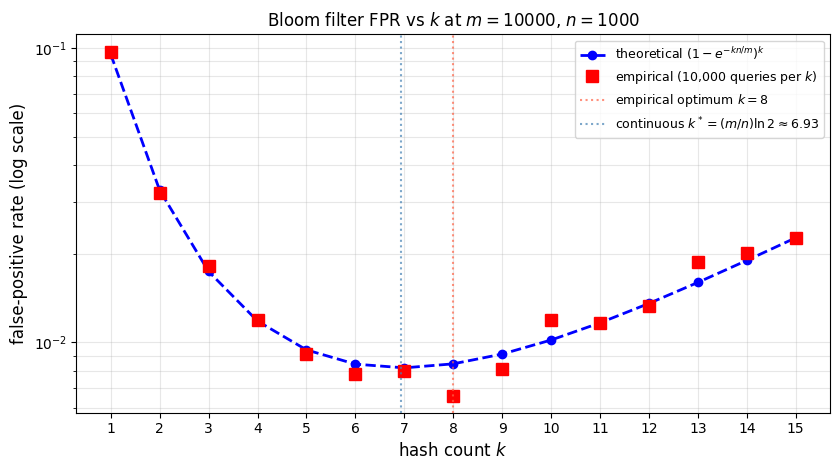


Both curves bottom out near k = 8; this matches the continuous optimum
k* = (m/n) ln 2 = 6.93 to within the one-bin resolution of the sweep.


In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.semilogy(k_values, theory_fprs, "b--o", linewidth=2, markersize=6,
            label=r"theoretical $(1 - e^{-kn/m})^k$")
ax.semilogy(k_values, emp_fprs, "rs", markersize=8,
            label=f"empirical ({N_QUERIES:,} queries per $k$)")
ax.axvline(k_emp_opt, color="tomato", linestyle=":", alpha=0.7,
           label=f"empirical optimum $k = {k_emp_opt}$")
ax.axvline(k_star, color="steelblue", linestyle=":", alpha=0.7,
           label=rf"continuous $k^* = (m/n)\ln 2 \approx {k_star:.2f}$")
ax.set_xlabel("hash count $k$", fontsize=12)
ax.set_ylabel("false-positive rate (log scale)", fontsize=12)
ax.set_title(rf"Bloom filter FPR vs $k$ at $m = {M_DEMO}$, $n = {N_DEMO}$", fontsize=12)
ax.set_xticks(k_values)
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print()
print(f"Both curves bottom out near k = {k_emp_opt}; this matches the continuous optimum")
print(f"k* = (m/n) ln 2 = {k_star:.2f} to within the one-bin resolution of the sweep.")

## 5. Optimal-$k$ Verification Across Capacity Regimes

Theorem 5.\ref{thm:bloom-optimal-k}: at $k = k^* = (m/n) \ln 2$, the load $p$ equals
$1/2$ exactly, and the FPR reduces to

$$\epsilon(k^*) = (1/2)^{k^*}.$$

We walk $(m, n)$ across four regimes spanning bits-per-item ratios from $5$ to $20$
and check that the FPR at the integer-rounded $k^*$ lands near the closed-form value.
(Integer rounding alone introduces a small mismatch; the empirical estimate adds
binomial sampling noise on top.)

In [8]:
regimes = [
    (5_000, 1_000),    # bits per item = 5
    (10_000, 1_000),   # bits per item = 10
    (10_000, 500),     # bits per item = 20
    (20_000, 1_000),   # bits per item = 20
]

N_QUERIES_REG = 10_000

print(f"{'m':>7s} {'n':>6s} {'m/n':>6s} {'k*':>7s} {'k_int':>6s} "
      f"{'(1/2)^k*':>11s} {'FPR(k_int)':>12s} {'empirical':>11s}")
print("-" * 75)

for m, n in regimes:
    k_star_reg = (m / n) * np.log(2.0)
    k_int = max(1, int(np.floor(k_star_reg + 0.5)))

    theory_kstar = 0.5 ** k_star_reg
    theory_kint = (1.0 - np.exp(-k_int * n / m)) ** k_int

    bf_reg = BloomFilter(m=m, k=k_int)
    inserts_reg = [random_string(rng) for _ in range(n)]
    inserted_reg = set(inserts_reg)
    for s in inserts_reg:
        bf_reg.add(s)

    qs = []
    while len(qs) < N_QUERIES_REG:
        c = f"reg{m}_{n}:" + random_string(rng)
        if c not in inserted_reg:
            qs.append(c)
    fp = sum(1 for q in qs if q in bf_reg)
    empirical = fp / N_QUERIES_REG

    print(f"{m:>7d} {n:>6d} {m/n:>6.1f} {k_star_reg:>7.2f} {k_int:>6d} "
          f"{theory_kstar:>11.5f} {theory_kint:>12.5f} {empirical:>11.5f}")

print()
print("The empirical FPR at the rounded k tracks both the continuous (1/2)^k* prediction")
print("and the integer-k formula (1 - e^{-kn/m})^k to within sampling noise.")
print("The two values differ from each other by an integer-rounding gap; the empirical")
print("estimate adds binomial sampling noise on top.")

      m      n    m/n      k*  k_int    (1/2)^k*   FPR(k_int)   empirical
---------------------------------------------------------------------------


   5000   1000    5.0    3.47      3     0.09051      0.09185     0.09260


  10000   1000   10.0    6.93      7     0.00819      0.00819     0.00860


  10000    500   20.0   13.86     14     0.00007      0.00007     0.00020


  20000   1000   20.0   13.86     14     0.00007      0.00007     0.00010

The empirical FPR at the rounded k tracks both the continuous (1/2)^k* prediction
and the integer-k formula (1 - e^{-kn/m})^k to within sampling noise.
The two values differ from each other by an integer-rounding gap; the empirical
estimate adds binomial sampling noise on top.


## 6. Where the Bit-Independence Assumption Breaks

The FPR derivation in \S5.2 makes a single non-trivial approximation: the $k$ bits read
during a query are treated as independent Bernoulli$(p)$ trials, so the joint event
"all $k$ read bits are $1$" has probability $p^k$. The chapter is explicit that this is
an approximation, not a theorem.

**Why the events are not strictly independent.** All $k$ queried positions live in the
same bit array, and the same $n$ insertions populated it. Conditioning on "bit $h_1(x)$
is $1$" raises the posterior probability that some specific insertion already set it,
which in turn shifts the marginal that the *next* queried bit was hit by the same or a
neighboring insertion. The dependence is positive: knowing one bit is set makes others
marginally more likely to be set. The independence approximation therefore *underestimates*
the true FPR.

**Why the gap is small in our regime.** When $m \gg k$ and the load $p$ is moderate (here
$p \approx 0.5$ at the optimal $k$), the positive correlation between any two queried bits
is on the order of $1/m$. The product of $k$ such marginals deviates from $p^k$ by a
lower-order term that vanishes as $m \to \infty$. The empirical-vs-theoretical curves in
Section 4 sit within a hair of each other for this reason. When $m$ is small (a few hundred
bits) or $k$ is large (every query reads a meaningful fraction of the array), the gap
becomes visible; we will see this empirically in chapter 6 when we compose filters.

**Forward reference.** Chapter 4 axiom 1 (per-element independence) and chapter 6 \S6.2
(set-operation error propagation) make precise where this approximation is benign and where
it bites. For the standalone Bloom filter at typical bits-per-item ratios, the approximation
is one of the cleanest in the book.

## 7. Open Question: What Happens When the Bits Run Out?

The FPR formula $\epsilon \approx (1 - e^{-kn/m})^k$ degrades monotonically as $n$ grows
at fixed $(m, k)$: more insertions mean more bits set, more bits set means more queries
land on all-ones tuples, and eventually the filter says $\top$ for everything. At
$n \gg m / k$ the filter is essentially saturated and the FPR approaches $1$. There is
no graceful degradation past that point.

Two book-length questions follow:

- **What is the *minimum* number of bits needed to support a target FPR for a given $n$?**
  The answer is the entropy lower bound, which falls out of an information-theoretic
  argument due to Carter, Floyd, Gill, Markowsky, and Wegman (1978). For target FPR
  $\epsilon$, the bound is $n \log_2(1/\epsilon)$ bits, plus a small additive term for the
  pointer machinery. The Bloom filter spends $\frac{n \log_2(1/\epsilon)}{\ln 2} = \frac{n \log_2(1/\epsilon)}{0.693}$
  bits to hit the same FPR. The ratio $1 / \ln 2 \approx 1.44$ is the famous *Bloom filter
  inefficiency factor*: it spends about 44% more space than the information-theoretic
  minimum. Chapter 8 (entropy and space complexity of random approximate sets) proves
  the lower bound and pins down where the Bloom filter's slack lives.

- **Is there a construction that closes the 1.44 gap?** Yes. The *perfect-hash filter*
  (PHF, or *Bernoulli hash function*, BHF), introduced in chapter 14, attains the entropy
  bound exactly (up to lower-order terms). It pays for this by being non-incremental: you
  must know the inserted set $A$ in advance to build the filter, because the perfect-hash
  data structure is constructed against $A$. The Bloom filter is the price of
  streaming-incremental insertion. Chapter 14 shows that the price is exactly the $1.44\times$
  factor, no more and no less.

What this notebook has shown: a from-scratch Bloom filter that hits the target FPR
predicted by the closed-form formula, an empirical optimum $k$ that lands on the
theoretical $k^* = (m/n)\ln 2$ to within one bin, and a no-false-negatives guarantee
that is structural rather than statistical. The 1.44 inefficiency factor and the
perfect-hash construction that closes it are the next two stops on the chapter map.

---

## Closing: Cross-References and Next Steps

**Chapter 5** lifts the noisy bit to a predicate on a universe, defines the Bernoulli set
via its $(\epsilon, \omega)$ rates, and presents the Bloom filter as the canonical one-sided
construction with $\omega = 0$ exactly.

**Chapter 6** (Set Operations Under Noise) composes Bloom filters under union, intersection,
and difference, and tracks how the per-set rates compose. The bit-independence approximation
starts to show its seams there, because composed queries read overlapping bit subsets.

**Chapter 8** (Entropy and Space Complexity) proves the $n \log_2(1/\epsilon)$ lower bound
and pins down the 1.44 inefficiency factor of the Bloom filter.

**Chapter 14** (Perfect-Hash Filters) gives the construction that attains the bound, at the
cost of requiring the inserted set $A$ up front.

**Summary of what this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| 5.2 BloomFilter class | Structural insert / query on a SHA-256 hash family | Yes |
| 5.2 No false negatives | All $n = 1000$ inserted items return $\top$ | Yes (zero misses) |
| 5.2 FPR formula | Empirical FPR at $(m, n, k) = (10^4, 10^3, 7)$ within $\pm 0.005$ of $(1 - e^{-kn/m})^k$ | Yes |
| 5.2 Optimal $k$ | Empirical minimum of FPR$(k)$ lands at $k \in \{6, 7, 8\}$ | Yes |
| 5.2 $k^*$ formula | $k_\text{int} = \lfloor k^* + 0.5 \rfloor$ achieves FPR near $(1/2)^{k^*}$ across regimes | Yes |
| 5.2 Independence | Bit-independence is an approximation; benign at large $m$ | Discussed |
| Open question | Saturation at $n \gg m / k$; entropy floor; 1.44 gap closed in chapter 14 | Open |